# Day 14: Tartrate & Protein Stabilization, Crossflow Microfiltration, Dissolved Gas Packaging & Closure Shelf-Life Forecaster
**Project:** Wine Quality Prediction (UCI Machine Learning Repository)
**Author:** ML Engineering & Production Deployment Team
**Milestone:** Day 14 Enterprise Packaging & Finishing Platform Expansion

### Key Architectural Capabilities:
1. **Thermodynamic Tartrate Saturation & Cold Crystallization:** Models potassium bitartrate ($KHT$) Concentration Product ($CP = [K^+][HT^-]$), saturation temperature ($T_{sat}$), minicontact electrical conductivity drop ($\Delta \chi$), and dynamic contact crystallization kinetics ($-4^\circ\text{C}$ with $4\text{ g/L}$ seeding).
2. **Thermolabile Protein Haze & Langmuir Bentonite Optimization:** Simulates heat test ($80^\circ\text{C} / 2\text{h}$) nephelometric turbidity ($\Delta NTU$) and optimizes sodium bentonite dosage via Langmuir adsorption isotherms while quantifying volatile aroma stripping penalties.
3. **Crossflow Membrane Microfiltration (0.45 $\mu$m PES):** Solves Hermia's filtration blocking rate laws, transmembrane pressure (TMP), permeate flux decline $J(t)$, turbidity clarification ($NTU < 0.6$), and Filterability Index ($FI$).
4. **Dissolved Gas Packaging Dynamics & Sparging:** Computes Henry's Law solubility equilibria for $DO$ and $CO_2$, micro-bubble counter-current nitrogen sparging deoxygenation, Total Packaging Oxygen ($TPO$), and antioxidant Free $SO_2$ stoichiometric depletion.
5. **Multi-Closure Permeation & Predictive Shelf-Life Forecaster:** Solves 0-48 month coupled ODEs for Oxygen Transmission Rate (OTR), Free $SO_2$ decay, spectrophotometric browning ($A_{420}$), organoleptic freshness, and PremOx breach boundaries across Natural Cork, Diam, Nomacorc, and Screwcaps.
6. **Bottling Line Statistical Process Control (SPC) Auditor:** Evaluates net fill volume ($750\text{ mL} \pm 1.5\%$ MAV legal metrology), closure insertion depth, and filter membrane bubble point integrity ($> 3.2\text{ bar}$).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()) if Path('..').resolve().name != 'Wine Quality Prediction' else str(Path('.').resolve()))
import json
import numpy as np
import pandas as pd

from src.stabilization_and_packaging import (
    TartrateStabilizationSimulator,
    ProteinHazeAndBentoniteOptimizer,
    CrossflowFiltrationSimulator,
    DissolvedGasPackagingEngine,
    ClosureShelfLifeForecaster,
    BottlingLineQCAuditor,
    CLOSURE_PROFILES,
    STABILIZATION_ADDITIVES
)
print('Successfully loaded Day 14 Stabilization, Membrane Filtration & Packaging Modules!')

Successfully loaded Day 14 Stabilization, Membrane Filtration & Packaging Modules!


## 1. Thermodynamic Tartrate Saturation & Cold Contact Kinetics

Evaluates the thermodynamic equilibrium of potassium bitartrate ($KHT$) and simulates chilled contact seeding.

In [2]:
tartrate_sim = TartrateStabilizationSimulator()

# Evaluate specimen under cellar storage (14°C)
eval_res = tartrate_sim.evaluate_tartrate_stability(
    tartaric_acid_g_l=7.2,
    potassium_mg_l=1150.0,
    ph=3.55,
    alcohol_pct=13.5,
    storage_temp_c=14.0
)
print('Tartrate Saturation Assessment:')
print(f'  Concentration Product (CP): {eval_res["concentration_product_cp"]:.2e} (mol/L)^2')
print(f'  Solubility Product (K_sp):  {eval_res["solubility_product_ksp"]:.2e} (mol/L)^2')
print(f'  Saturation Ratio:           {eval_res["saturation_ratio"]:.2f}')
print(f'  Saturation Temp (T_sat):    {eval_res["saturation_temperature_c"]} °C')
print(f'  Minicontact Drop (Delta chi): {eval_res["minicontact_delta_chi_us_cm"]} uS/cm')
print(f'  Stability Classification:   {eval_res["stability_status"]}')

# Dynamic contact crystallization simulation at -4°C with 4 g/L seed crystals
sim_res = tartrate_sim.simulate_cold_stabilization_kinetics(
    tartaric_acid_g_l=7.2,
    potassium_mg_l=1150.0,
    ph=3.55,
    alcohol_pct=13.5,
    chilling_temp_c=-4.0,
    seed_crystal_g_l=4.0,
    duration_hours=12
)
traj_df = pd.DataFrame(sim_res['trajectory'])
print(f'Precipitated KHT: {sim_res["final_state"]["total_kht_precipitated_g_l"]} g/L')
print(f'Post-Stabilization Drop: {sim_res["final_state"]["minicontact_delta_chi_us_cm"]} uS/cm -> {sim_res["final_state"]["stability_status"]}')
traj_df.head()

Tartrate Saturation Assessment:
  Concentration Product (CP): 9.80e-04 (mol/L)^2
  Solubility Product (K_sp):  1.72e-04 (mol/L)^2
  Saturation Ratio:           5.71
  Saturation Temp (T_sat):    45.0 °C
  Minicontact Drop (Delta chi): 214.2 uS/cm
  Stability Classification:   UNSTABLE
Precipitated KHT: 3.879 g/L
Post-Stabilization Drop: 11.0 uS/cm -> STABLE


,hour,potassium_mg_l,tartaric_acid_g_l,kht_precipitated_g_l
0,0.00,1150.0,7.20,0.000
1,0.25,1105.5,7.03,0.214
2,0.50,1063.7,6.87,0.415
3,0.75,1024.3,6.72,0.605
4,1.00,987.1,6.57,0.784


## 2. Thermolabile Protein Haze & Langmuir Bentonite Optimization

Quantifies heat-induced haze risk and optimizes sodium bentonite dosage to preserve volatile aromas.

In [3]:
bentonite_opt = ProteinHazeAndBentoniteOptimizer()

haze_eval = bentonite_opt.evaluate_protein_haze_risk(protein_content_mg_l=130.0, ph=3.25, cultivar='white')
print('Heat Test Haze Evaluation (80°C / 2h):')
print(f'  Estimated Delta NTU: {haze_eval["estimated_heat_delta_ntu"]} NTU')
print(f'  Risk Category:      {haze_eval["risk_category"]}')

dose_opt = bentonite_opt.optimize_bentonite_dosage(
    protein_content_mg_l=130.0,
    ph=3.25,
    cultivar='white',
    bentonite_type='sodium_bentonite'
)
print('Langmuir Fining Optimization Result:')
print(f'  Recommended Dosage:   {dose_opt["recommended_bentonite_g_hl"]} g/hL')
print(f'  Post-Fining Haze:     {dose_opt["heat_delta_ntu_final"]} Delta NTU (Target <= 1.8)')
print(f'  Aroma Stripping Loss: {dose_opt["aroma_stripping_penalty_pct"]} %')

Heat Test Haze Evaluation (80°C / 2h):
  Estimated Delta NTU: 29.95 NTU
  Risk Category:      SEVERE_HAZE_RISK
Langmuir Fining Optimization Result:
  Recommended Dosage:   180.0 g/hL
  Post-Fining Haze:     1.66 Delta NTU (Target <= 1.8)
  Aroma Stripping Loss: 78.3 %


## 3. Crossflow Membrane Microfiltration (0.45 um PES)

Simulates permeate flux decline $J(t)$, periodic hydrodynamic backwash restoration, and brilliant clarification.

In [4]:
filt_sim = CrossflowFiltrationSimulator(membrane_surface_area_m2=40.0)

run_res = filt_sim.simulate_crossflow_run(
    initial_turbidity_ntu=38.0,
    transmembrane_pressure_bar=1.6,
    target_volume_liters=12000.0,
    colloidal_index=1.2,
    backwash_interval_hours=2.0,
    run_duration_hours=6.0
)
print('Filtration Performance Summary:')
for k, v in run_res['summary'].items():
    print(f'  {k}: {v}')

Filtration Performance Summary:
  total_volume_filtered_l: 12027.5
  duration_hours: 3.5
  average_flux_lmh: 83.5
  final_flux_lmh: 66.6
  final_permeate_turbidity_ntu: 0.54
  clarity_status: BRILLIANT_STERILE
  filterability_index_s: 28.1
  clogging_risk: MEDIUM


## 4. Dissolved Gas Management, N2 Sparging & Total Packaging Oxygen (TPO)

Evaluates micro-bubble deoxygenation efficiency and calculates Total Packaging Oxygen (TPO).

In [5]:
gas_eng = DissolvedGasPackagingEngine()

# Micro-bubble N2 sparging
sparge_res = gas_eng.simulate_nitrogen_sparging(
    initial_do_mg_l=1.40,
    target_do_mg_l=0.40,
    nitrogen_flow_ratio_nl_l=0.6,
    temperature_c=18.0
)
print('Nitrogen Sparging Results:')
print(f'  Initial DO: {sparge_res["initial_do_mg_l"]} mg/L -> Final DO: {sparge_res["final_do_mg_l"]} mg/L')
print(f'  Efficiency: {sparge_res["deoxygenation_efficiency_pct"]} % | Target Reached: {sparge_res["target_reached"]}')

# TPO calculation with vacuum corker inert gas flush (1.5% O2 in headspace)
tpo_res = gas_eng.calculate_total_packaging_oxygen(
    dissolved_oxygen_wine_mg_l=sparge_res["final_do_mg_l"],
    headspace_volume_ml=6.0,
    bottle_volume_ml=750.0,
    headspace_o2_pct=1.5
)
print('TPO Packaging Assessment:')
print(f'  Total Packaging Oxygen: {tpo_res["total_packaging_oxygen_tpo_mg_l"]} mg/L')
print(f'  Grade:                  {tpo_res["tpo_grade"]}')
print(f'  Stoichiometric SO2 Hit: {tpo_res["stoichiometric_free_so2_depletion_mg_l"]} mg/L')

Nitrogen Sparging Results:
  Initial DO: 1.4 mg/L -> Final DO: 0.26 mg/L
  Efficiency: 81.5 % | Target Reached: True
TPO Packaging Assessment:
  Total Packaging Oxygen: 0.42 mg/L
  Grade:                  EXCELLENT_PREMIUM
  Stoichiometric SO2 Hit: 1.68 mg/L


## 5. Packaging Closure Permeation & 48-Month Shelf-Life Forecaster

Forecasts Free $SO_2$ depletion, browning index ($A_{420}$), and PremOx boundaries across closures.

In [6]:
shelf_forecaster = ClosureShelfLifeForecaster()

c_res = shelf_forecaster.simulate_bottle_shelf_life(
    closure_type='diam_5_microagglomerated',
    initial_free_so2=32.0,
    initial_ph=3.45,
    initial_tpo_mg_l=tpo_res["total_packaging_oxygen_tpo_mg_l"],
    storage_temperature_c=14.0,
    duration_months=48
)
print('Closure Aging Milestones (Diam 5 @ 14°C):')
for k, v in c_res['milestones'].items():
    print(f'  {k}: {v}')
print('Final 48-Month State:')
for k, v in c_res['final_state'].items():
    print(f'  {k}: {v}')

Closure Aging Milestones (Diam 5 @ 14°C):
  premox_breach_month: -1
  peak_maturity_month: 18
  commercial_shelf_life_months: 48
Final 48-Month State:
  free_so2_mg_l: 20.35
  molecular_so2_mg_l: 0.456
  a420_browning: 0.168
  freshness_score: 59.0


## 6. Bottling Line Statistical Process Control (SPC) Audit

Audits commercial batch fill volume metrology ($750\text{ mL} \pm 1.5\%$) and membrane integrity.

In [7]:
qc_auditor = BottlingLineQCAuditor()

np.random.seed(42)
sample_vols = [float(round(v, 2)) for v in np.random.normal(750.3, 1.6, 25)]
sample_depths = [float(round(d, 2)) for d in np.random.normal(1.05, 0.12, 25)]
sample_vacs = [float(round(vac, 3)) for vac in np.random.normal(-0.27, 0.03, 25)]

spc_report = qc_auditor.audit_bottling_batch(
    lot_id='LOT_ESTATE_CAB_B2026_01',
    fill_volumes_ml=sample_vols,
    closure_depths_mm=sample_depths,
    headspace_vacuums_bar=sample_vacs,
    filter_bubble_point_bar=3.45
)
print('Bottling Line SPC Audit Report:')
print(f'  Audit Tier:       {spc_report["audit_tier"]}')
print(f'  Approved:         {spc_report["is_batch_approved"]}')
print(f'  Mean Volume:      {spc_report["fill_volume_spc"]["mean_ml"]} mL (Nominal 750 mL)')
print(f'  Process Cpk:      {spc_report["fill_volume_spc"]["cpk"]}')
print(f'  Filter Integrity: Bubble Point {spc_report["membrane_integrity"]["bubble_point_bar"]} bar -> Passed={spc_report["membrane_integrity"]["passed"]}')

Bottling Line SPC Audit Report:
  Audit Tier:       SIX_SIGMA_COMPLIANT
  Approved:         True
  Mean Volume:      750.04 mL (Nominal 750 mL)
  Process Cpk:      2.44
  Filter Integrity: Bubble Point 3.45 bar -> Passed=True


## 7. Publication Diagnostic Figures Gallery

Display the four publication-grade diagnostic figures published in `reports/figures/`.

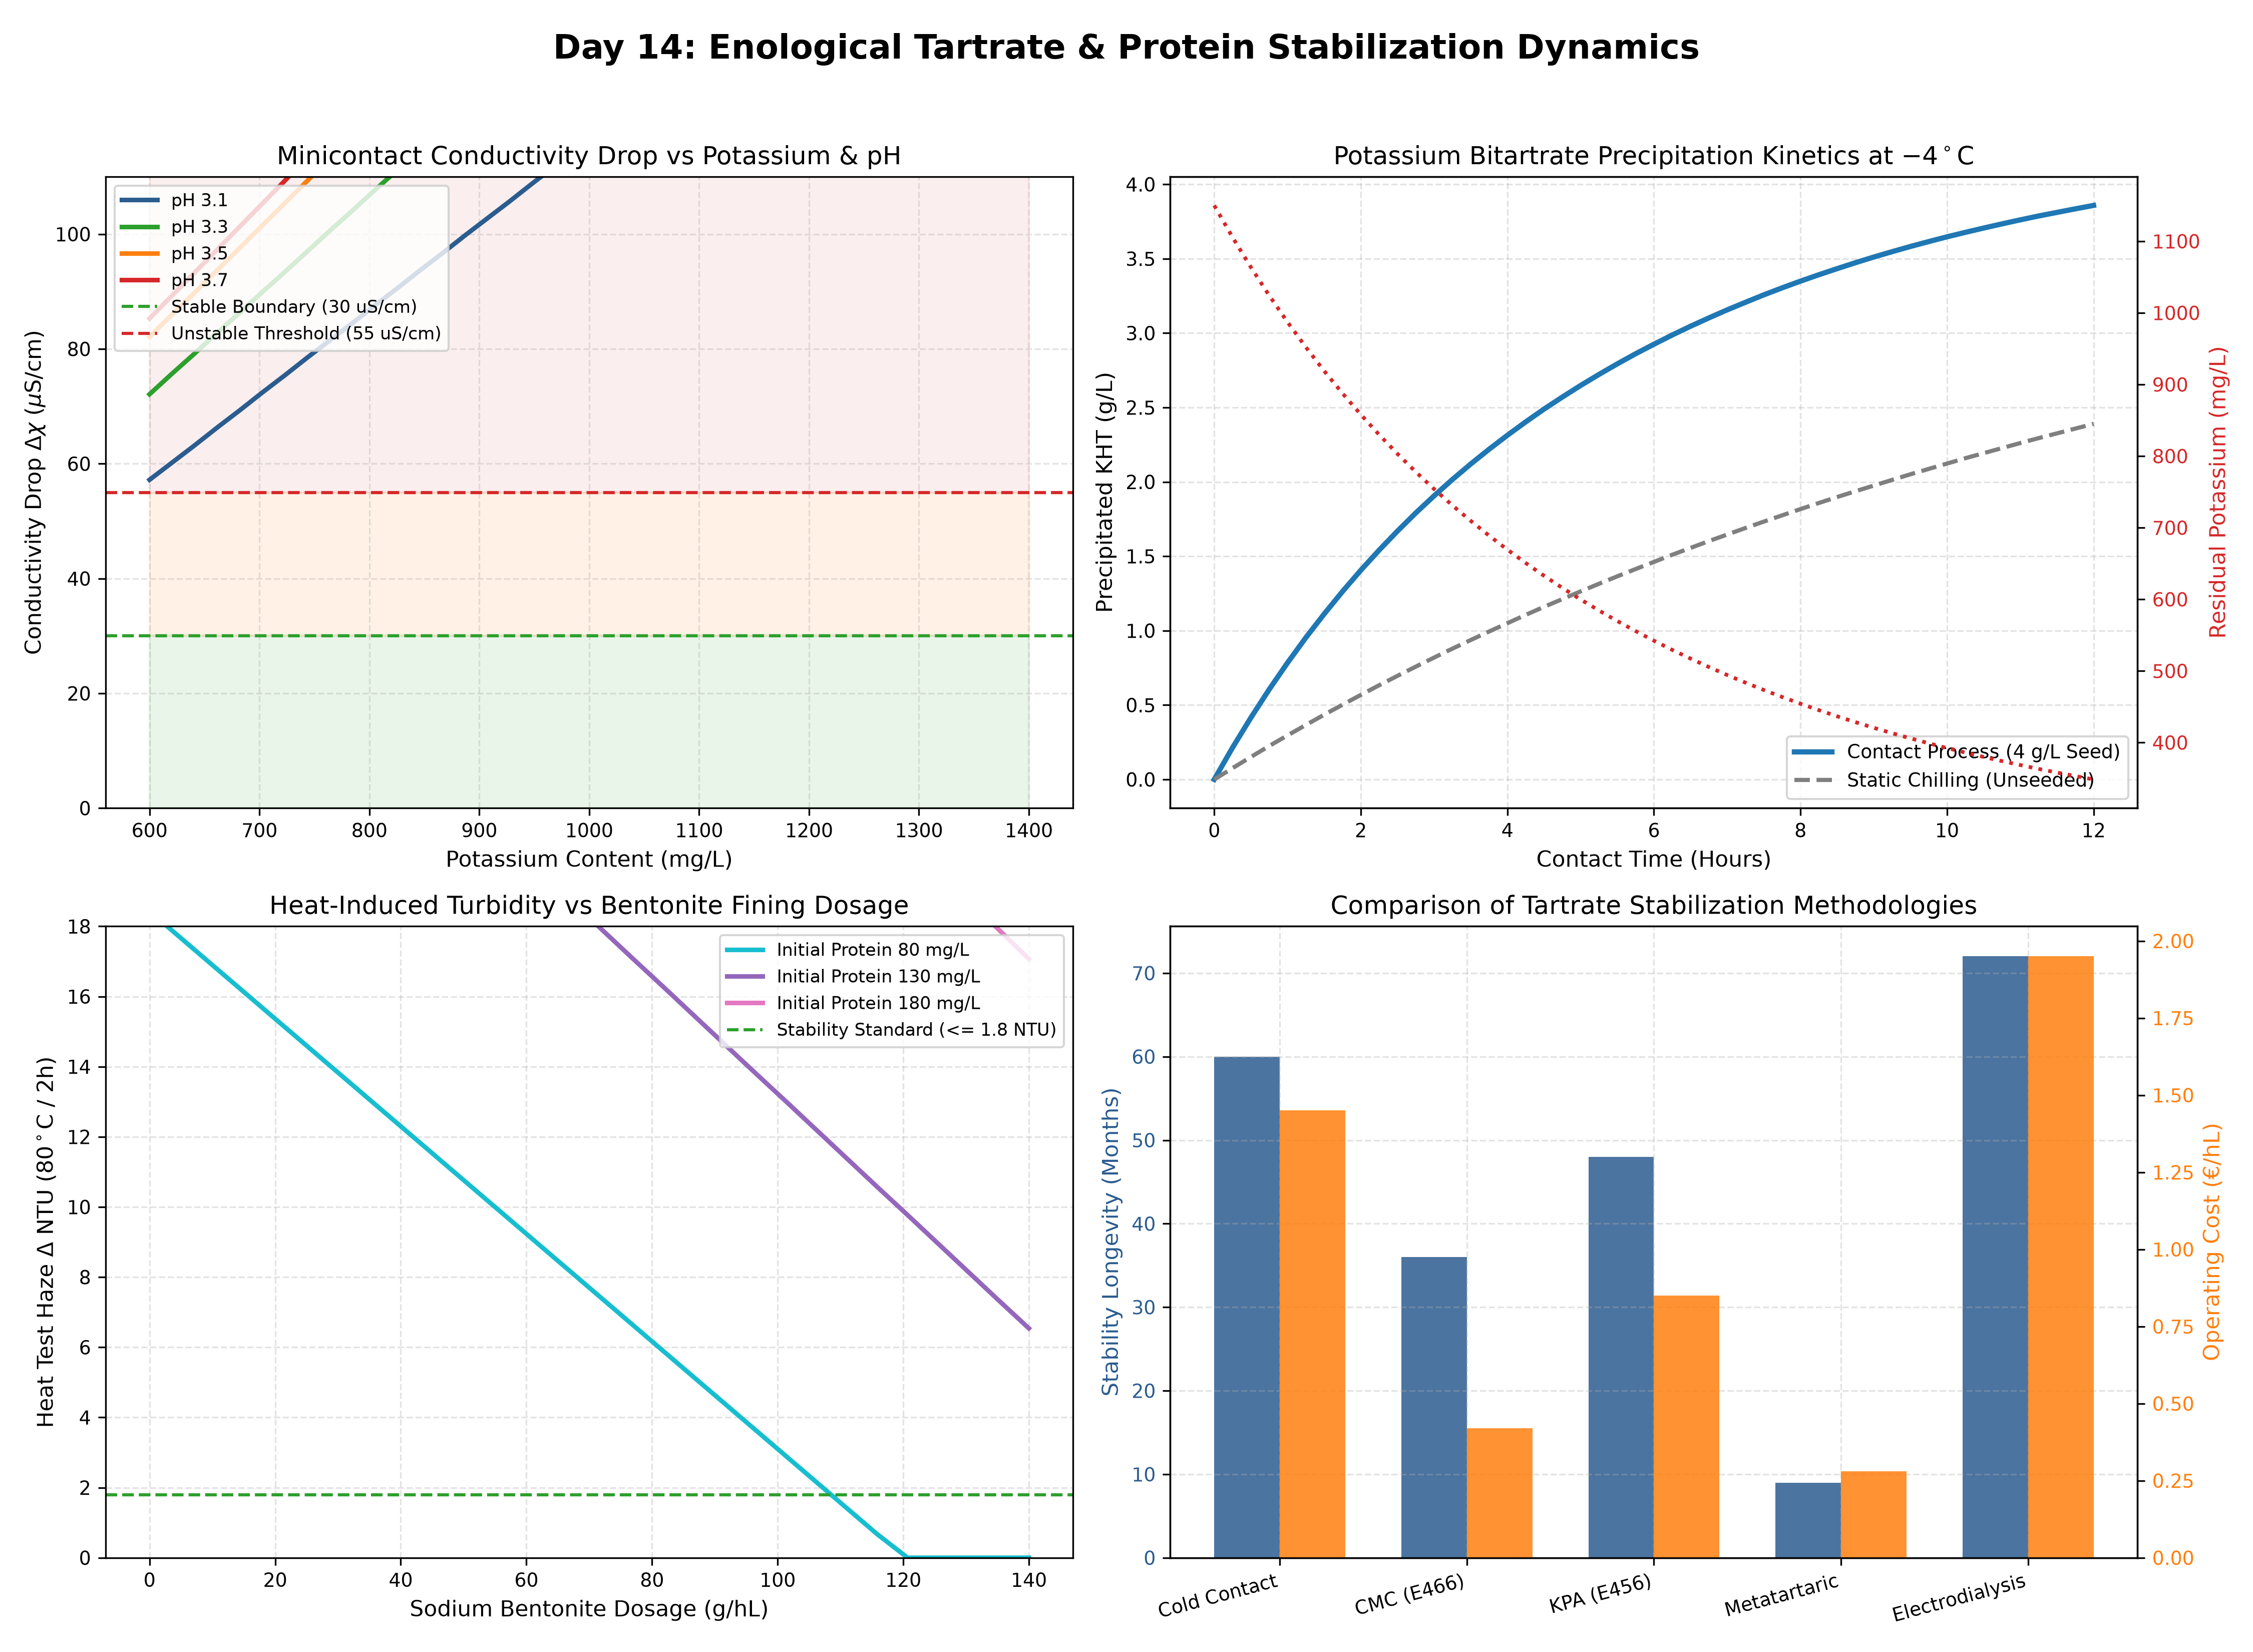

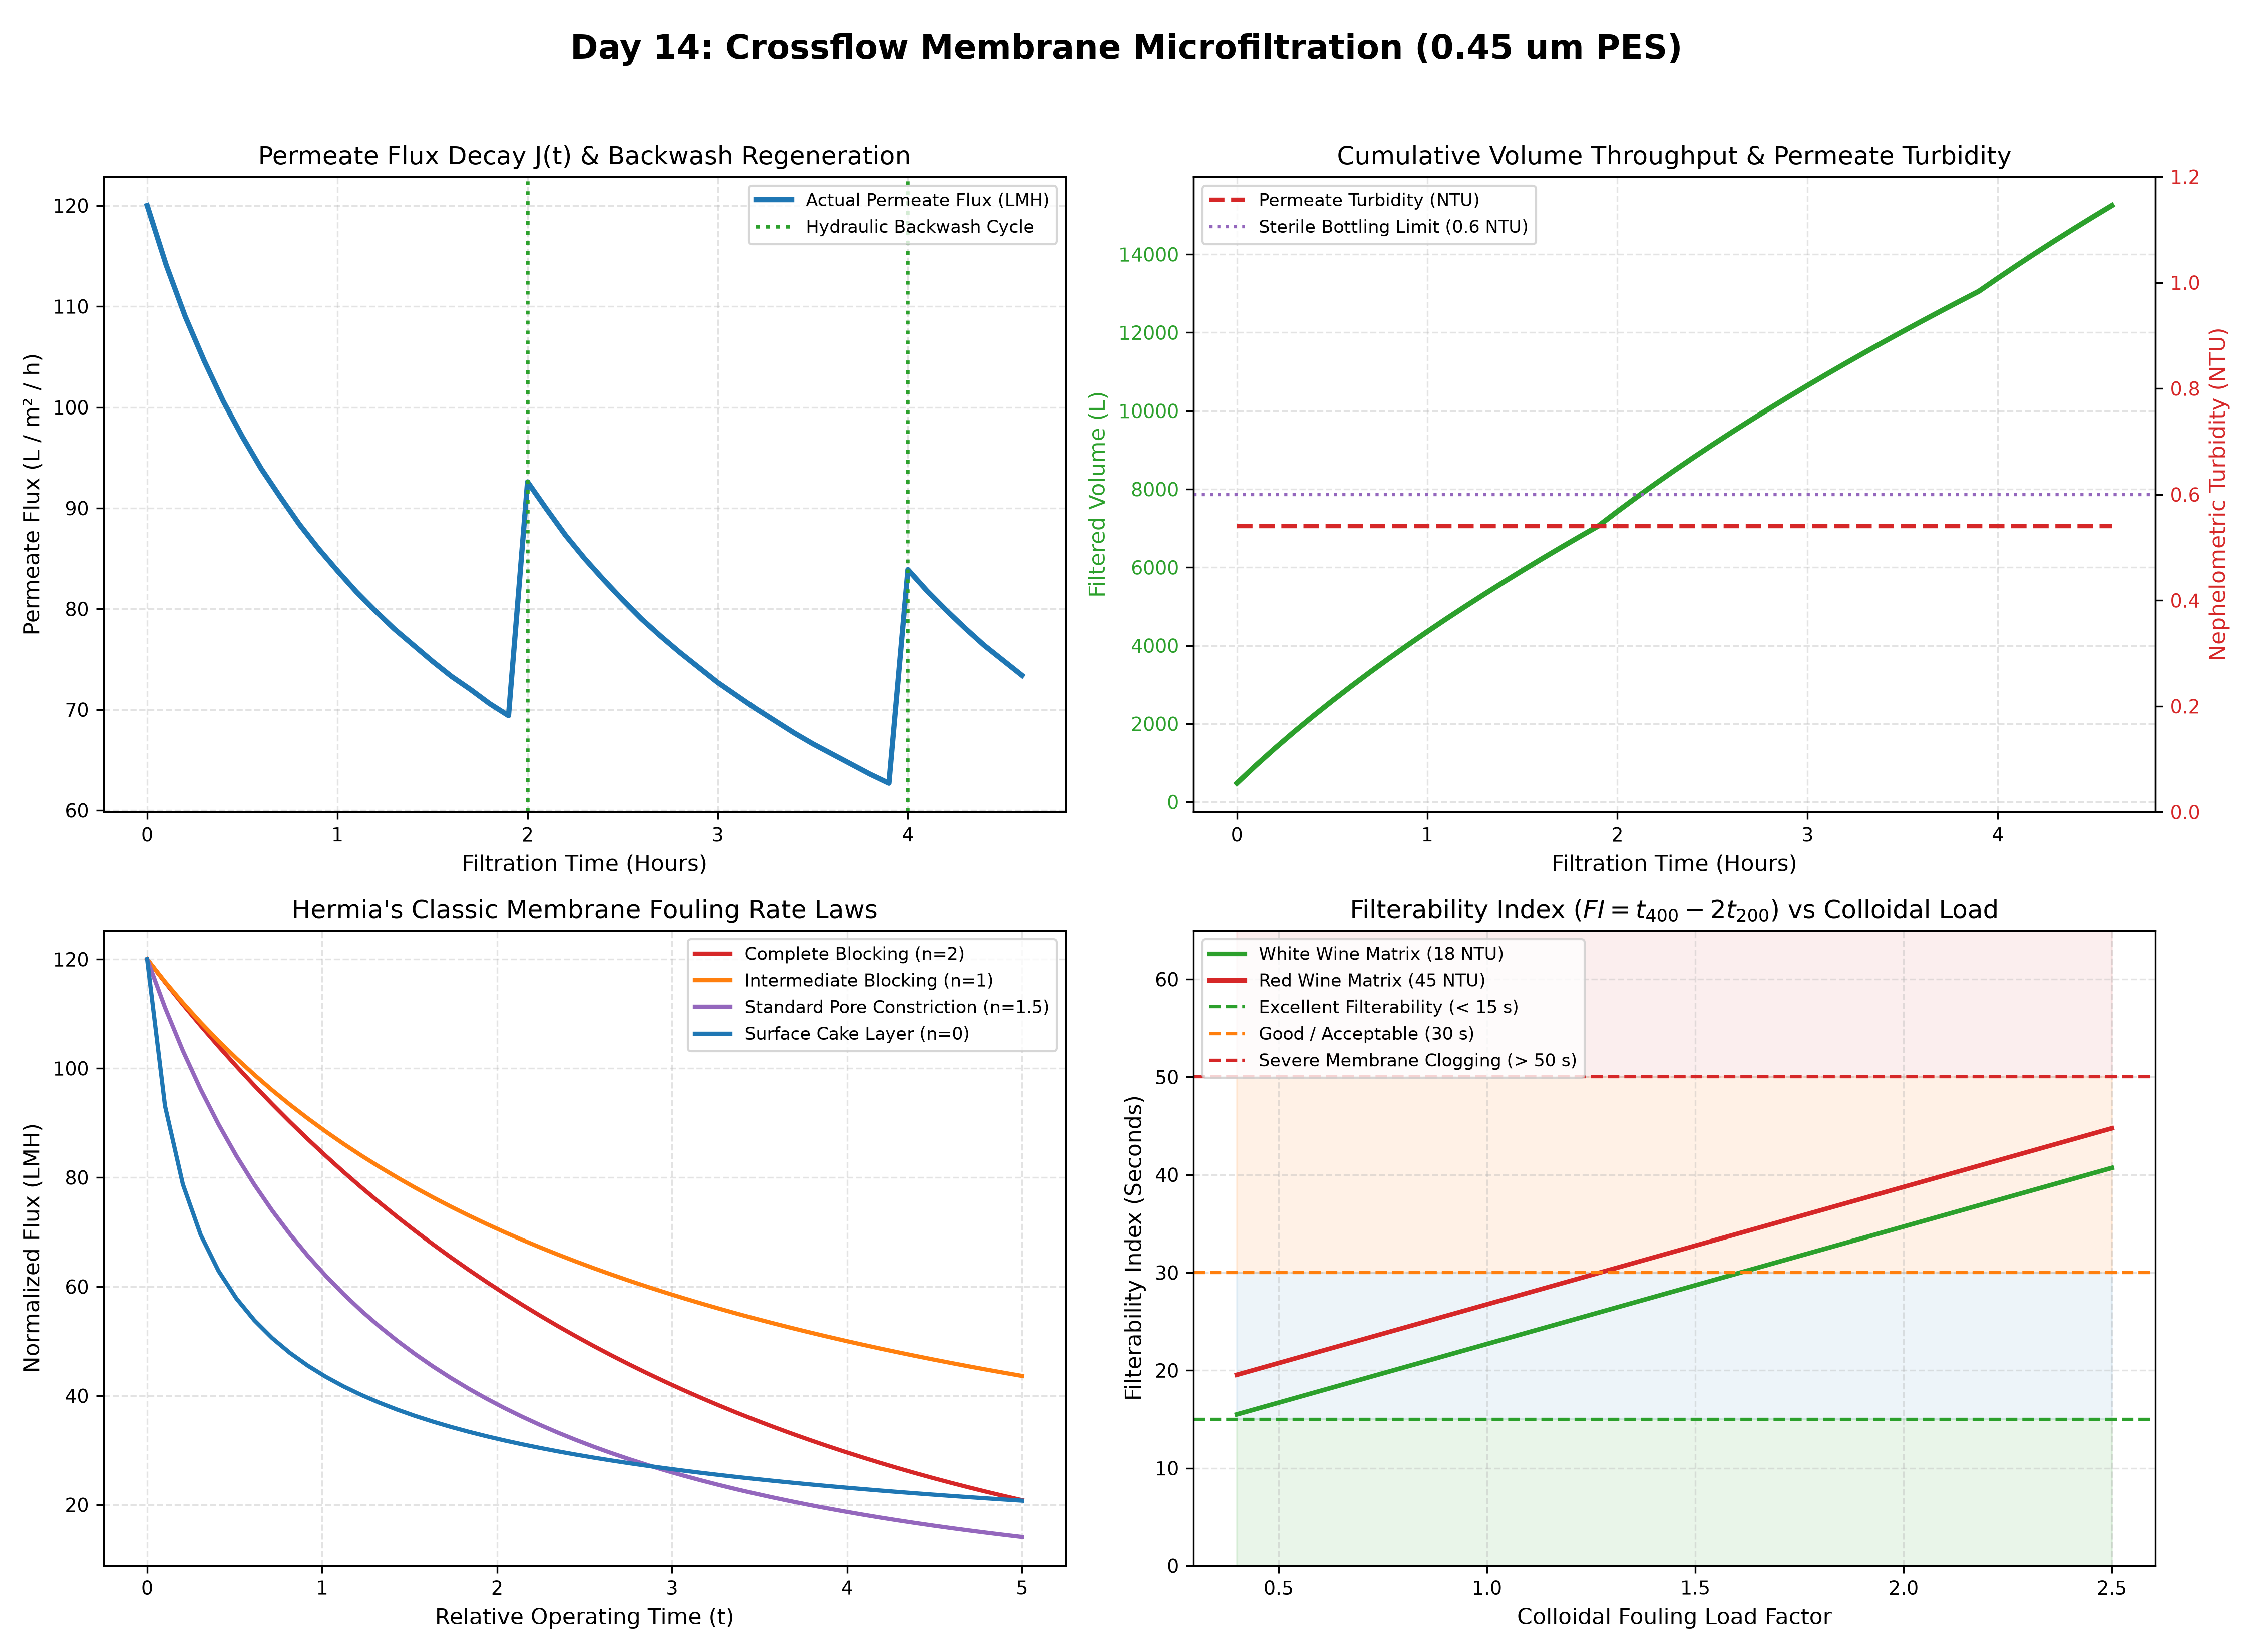

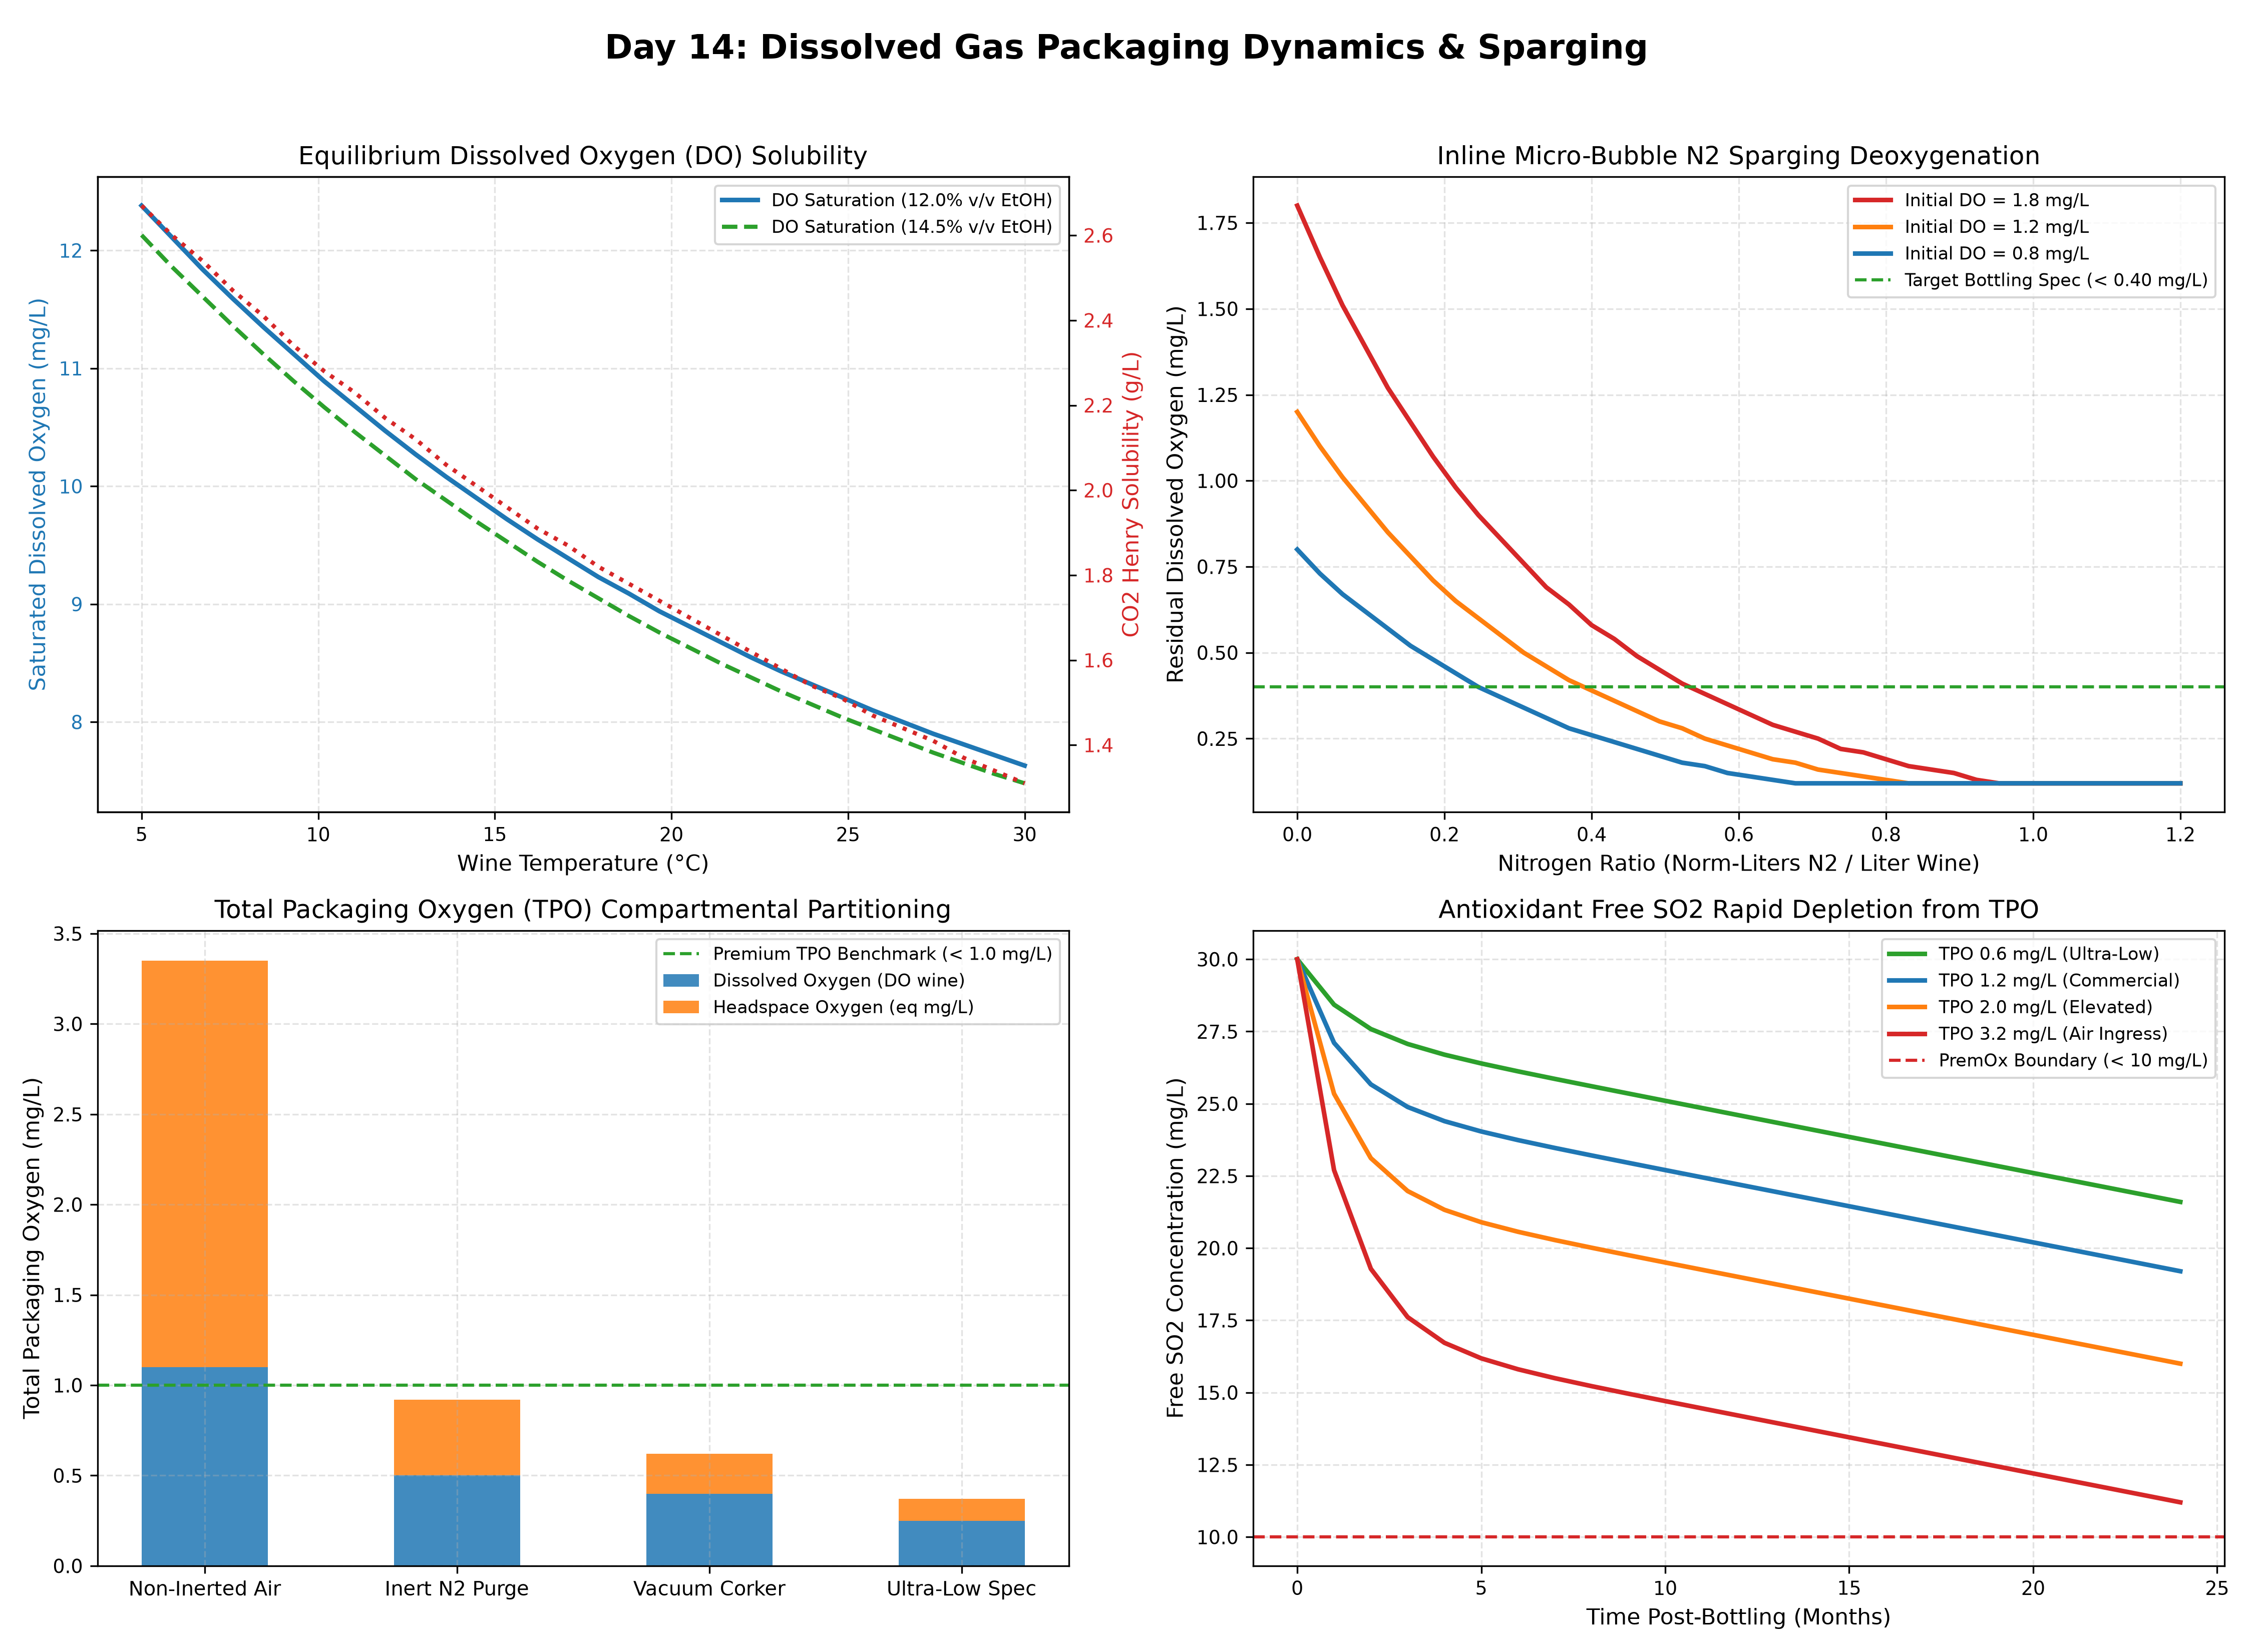

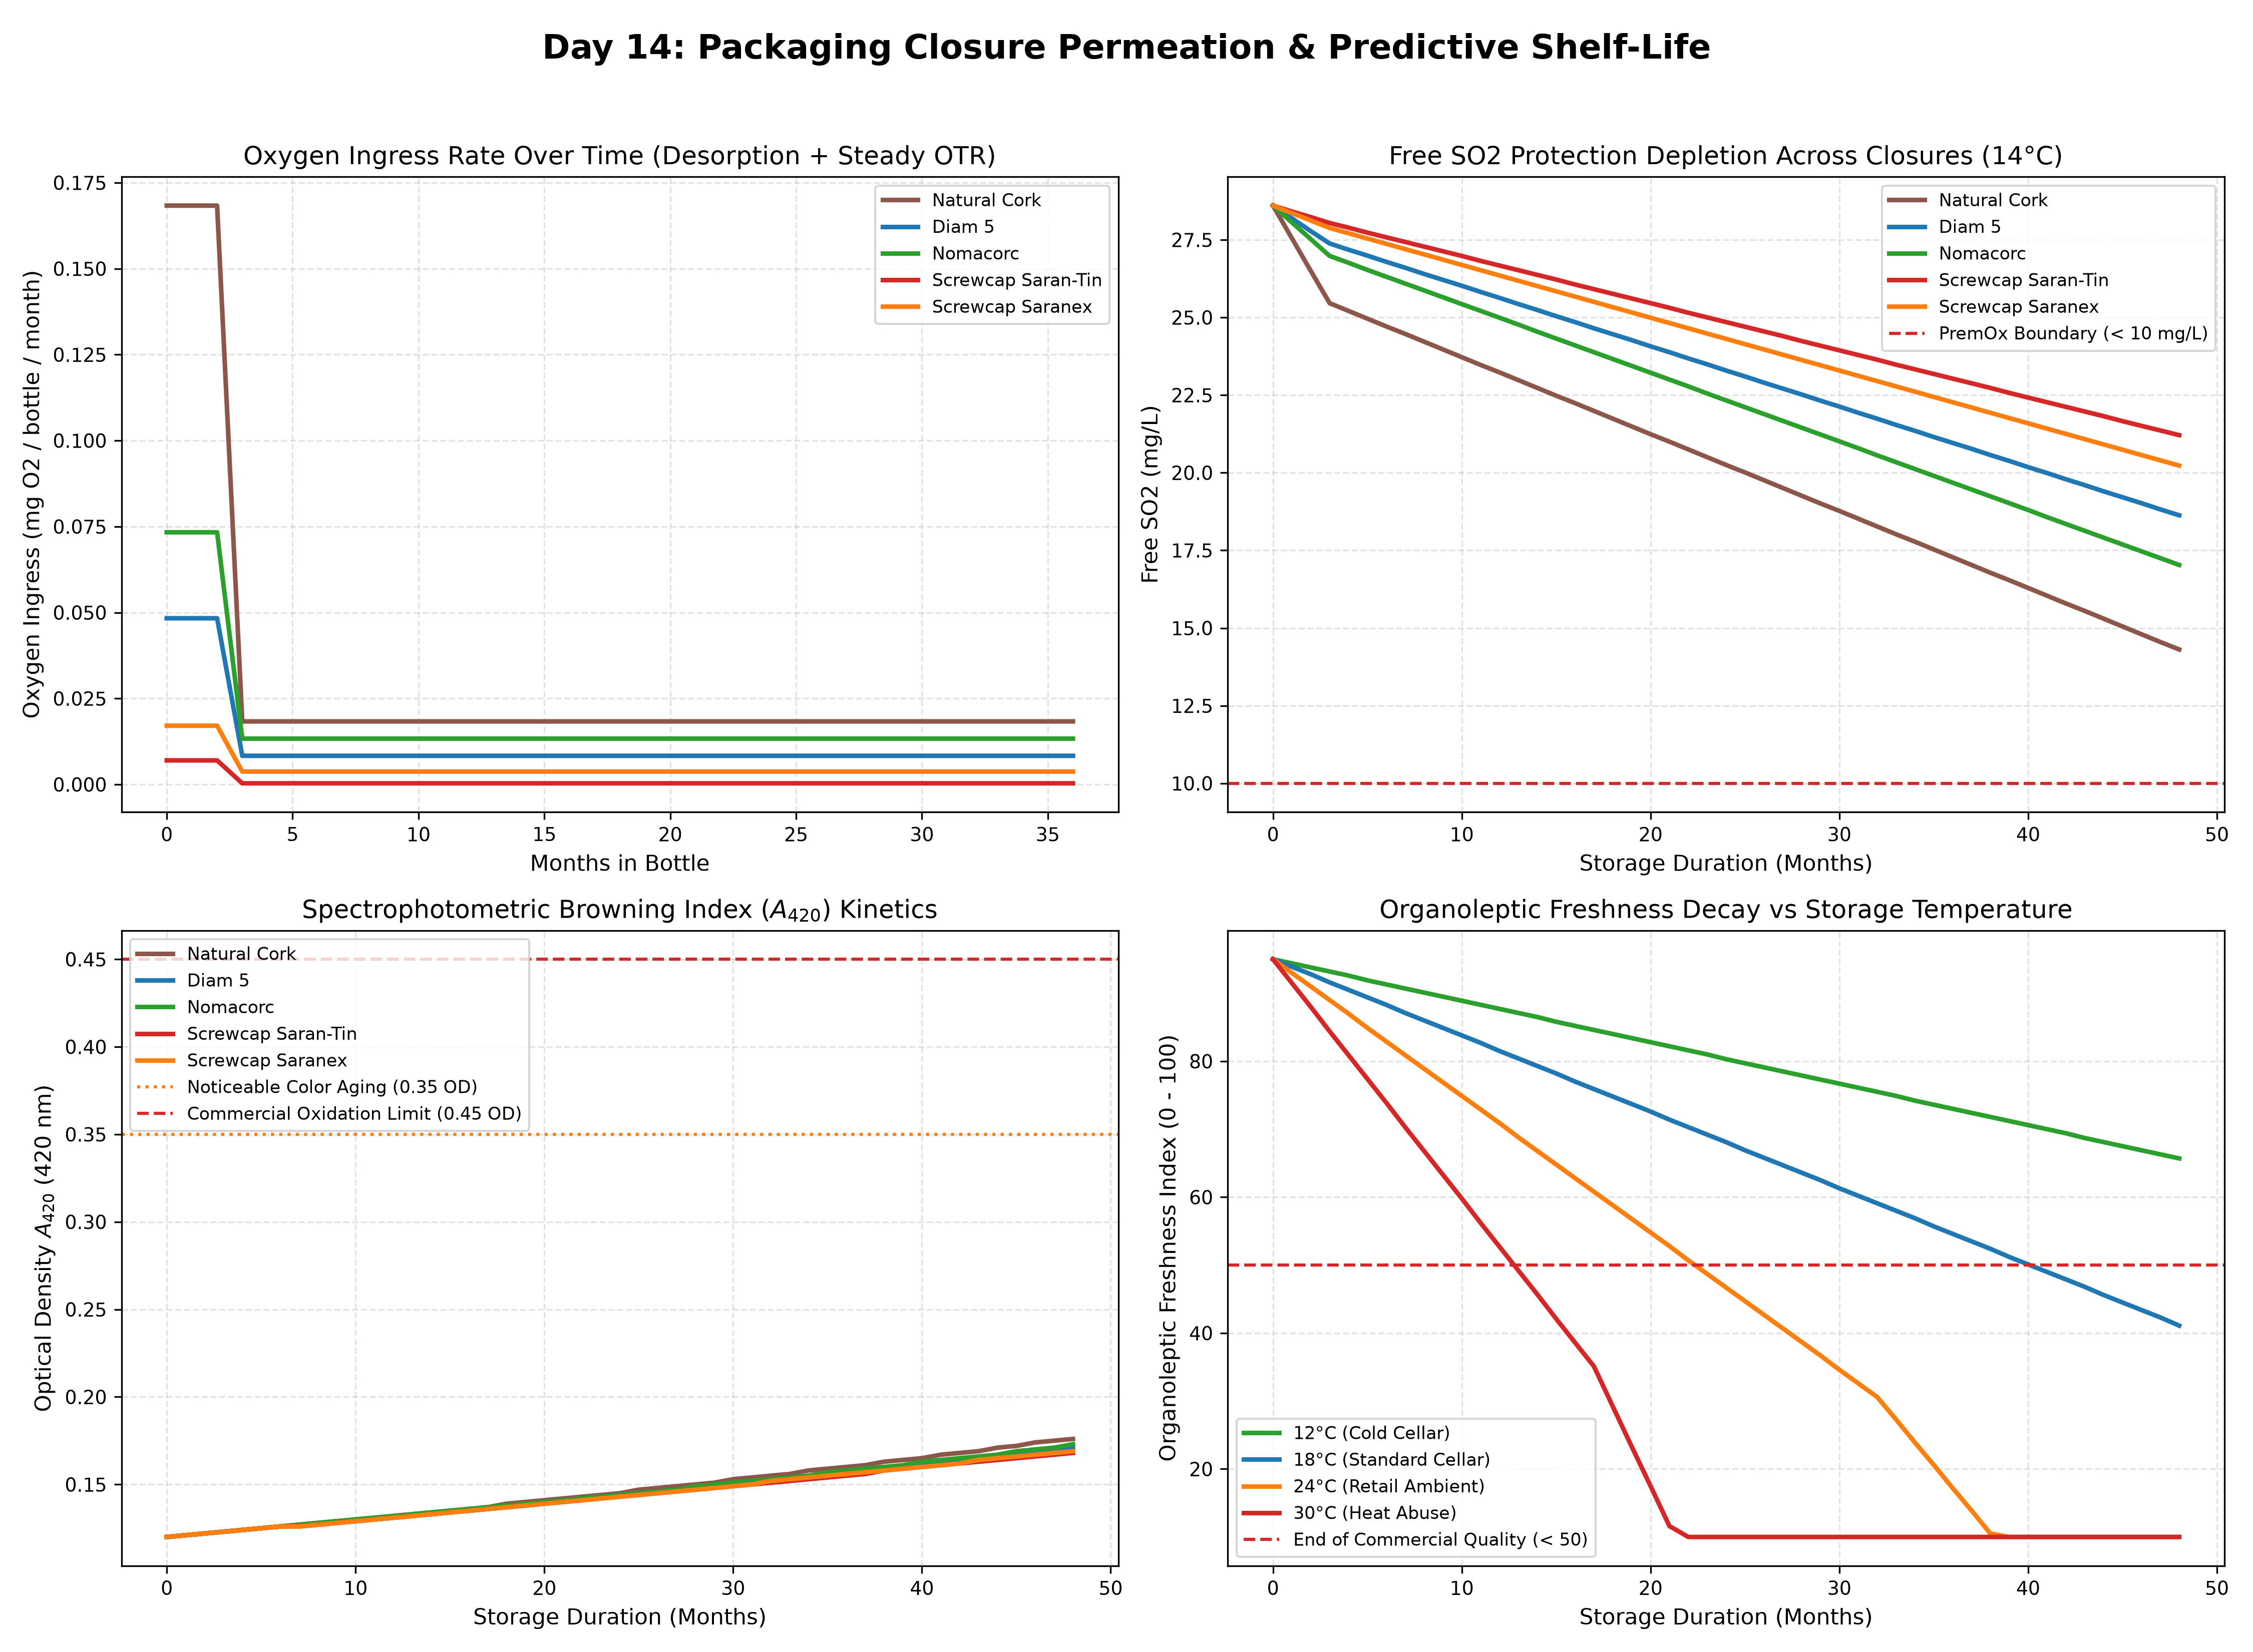

In [8]:
from IPython.display import Image, display
display(Image(filename='reports/figures/day14_tartrate_and_protein_stabilization.png'))
display(Image(filename='reports/figures/day14_crossflow_membrane_filtration.png'))
display(Image(filename='reports/figures/day14_dissolved_gas_and_sparging.png'))
display(Image(filename='reports/figures/day14_closure_permeation_and_shelf_life.png'))